<a href="https://colab.research.google.com/github/rodrigoesborges/conju-python/blob/main/Grupo_1_IBC_BR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [45]:
!pip install python-bcb

In [46]:
from bcb import sgs


In [47]:
sgs.get(24364)

,24364
Date,
2003-01-01,70.22674
2003-02-01,71.44564
2003-03-01,71.05748
2003-04-01,70.58011
2003-05-01,69.87411
...,...
2026-05-01,111.27562
2026-06-01,110.31795
2026-07-01,109.91887


In [48]:
import pandas as pd
from bcb import sgs

# Buscar dados da série 24364
df = sgs.get(24364)
df.index = pd.to_datetime(df.index)
col_nome = df.columns[0]

# Filtrar dados para os anos de 2025 e 2026
df_2025 = df[df.index.year == 2025].copy()
df_2026 = df[df.index.year == 2026].copy()

# Adicionar coluna de mês para fazer o alinhamento (join/merge)
df_2025['Mes'] = df_2025.index.month
df_2026['Mes'] = df_2026.index.month

# Mesclar os dados de 2025 e 2026 com base no mês
comparativo = pd.merge(df_2025, df_2026, on='Mes', suffixes=('_2025', '_2026'))

# Calcular a variação percentual
comparativo['Variacao_Anual (%)'] = ((comparativo[f'{col_nome}_2026'] / comparativo[f'{col_nome}_2025']) - 1) * 100

# Formatar e exibir os resultados
comparativo = comparativo.rename(columns={f'{col_nome}_2025': 'Valor_2025', f'{col_nome}_2026': 'Valor_2026'})
comparativo = comparativo[['Mes', 'Valor_2025', 'Valor_2026', 'Variacao_Anual (%)']]
display(comparativo)

,Mes,Valor_2025,Valor_2026,Variacao_Anual (%)
0,1,108.05569,110.20500,1.989076
1,2,108.54900,110.85559,2.124930
2,3,109.98458,110.64977,0.604803
3,4,109.47447,111.01392,1.406218
4,5,108.84792,111.27562,2.230360
5,6,108.73331,110.31795,1.457364
6,7,108.50375,109.91887,1.304213
7,8,108.79715,110.04903,1.150655
8,9,108.83935,109.77734,0.861811


/tmp/ipykernel_485/3030956185.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


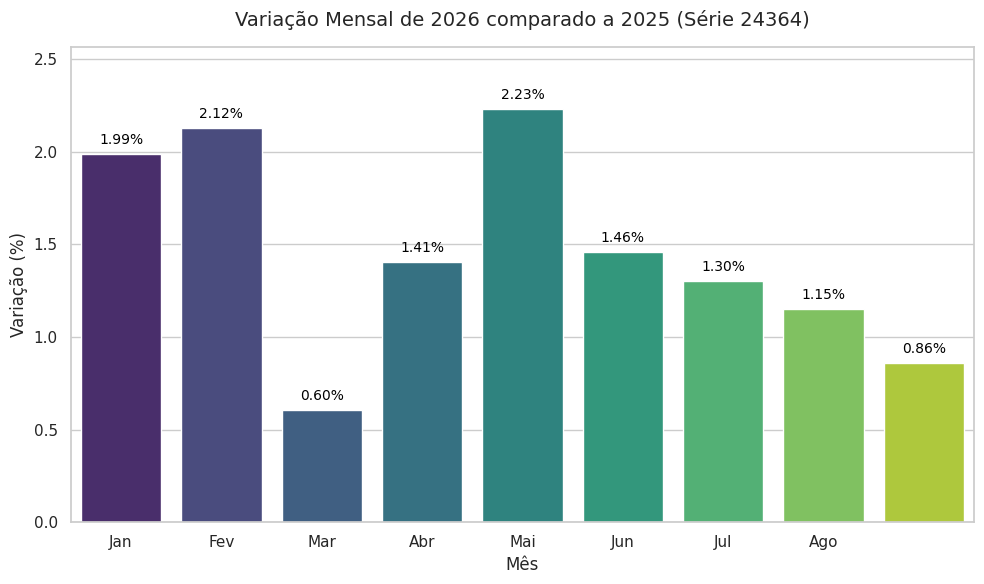

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo do gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Criar gráfico de barras
ax = sns.barplot(
    x='Mes',
    y='Variacao_Anual (%)',
    data=comparativo,
    palette='viridis'
)

# Adicionar os valores acima das barras
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

# Customizações estéticas
plt.title('Variação Mensal de 2026 comparado a 2025 (Série 24364)', fontsize=14, pad=15)
plt.xlabel('Mês', fontsize=12)
plt.ylabel('Variação (%)', fontsize=12)
plt.xticks(range(8), ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago']) # Ajustado para os meses disponíveis
plt.ylim(0, max(comparativo['Variacao_Anual (%)']) * 1.15)

plt.tight_layout()
plt.show()

In [50]:


resultado_12m = comparar_12_meses_atras(df, data_teste)
resultado_dez = comparar_dezembro_anterior(df, data_teste)

print("--- Comparação de 12 Meses Atrás ---")
if isinstance(resultado_12m, dict):
    for k, v in resultado_12m.items():
        if isinstance(v, float):
            print(f"{k}: {v:.4f}")
        else:
            print(f"{k}: {v}")
else:
    print(resultado_12m)

print("\n--- Comparação com Dezembro do Ano Anterior ---")
if isinstance(resultado_dez, dict):
    for k, v in resultado_dez.items():
        if isinstance(v, float):
            print(f"{k}: {v:.4f}")
        else:
            print(f"{k}: {v}")
else:
    print(resultado_dez)


data_teste = '2015-10-01'


--- Comparação de 12 Meses Atrás ---
Data Inserida: 2020-09-01
Valor Atual: 95.3506
Data 12m Antes: 2019-09-01
Valor Anterior: 96.9224
Variacao Absoluta: -1.5717
Variacao (%): -1.6217

--- Comparação com Dezembro do Ano Anterior ---
Data Inserida: 2020-09-01
Valor Atual: 95.3506
Data Dez. Anterior: 2019-12-01
Valor Dez. Anterior: 97.5709
Variacao Absoluta: -2.2203
Variacao (%): -2.2756
